<a href="https://colab.research.google.com/github/aishwaryaa-04/DS-SAT/blob/main/SAT2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Upload the CSV files (Google Colab)

In [ ]:
# If your five CSV files are already visible in Colab's Files panel, you can skip this cell.
# Otherwise, run it and select the five CSV files from your computer.
from google.colab import files
uploaded = files.upload()

Saving inventory.csv to inventory (3).csv
Saving products.csv to products (3).csv
Saving README.txt to README (2).txt
Saving stores.csv to stores (4).csv
Saving transactions.csv to transactions (4).csv
Saving external_factors.csv to external_factors (4).csv


## 2. Import libraries and load data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)

DATA_DIR = Path("/content")

transactions = pd.read_csv(DATA_DIR / "transactions.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
stores = pd.read_csv(DATA_DIR / "stores.csv")
inventory = pd.read_csv(DATA_DIR / "inventory.csv")
external = pd.read_csv(DATA_DIR / "external_factors.csv")

datasets_raw = {
    "Transactions": transactions,
    "Products": products,
    "Stores": stores,
    "Inventory": inventory,
    "External Factors": external
}

print("All datasets loaded successfully!")
for name, df in datasets_raw.items():
    print(f"{name}: {df.shape[0]} rows × {df.shape[1]} columns")
    display(df.head(3))

All datasets loaded successfully!
Transactions: 337 rows × 8 columns


,transaction_id,date,store_id,product_id,quantity,selling_price,discount_percent,promotion
0,T0001,2026-09-01,S01,P101,20,32,10,Yes
1,T0002,2026-09-01,S01,P102,17,40,0,No
2,T0003,2026-09-01,S01,P103,1,320,0,No


Products: 10 rows × 7 columns


,product_id,product_name,category,brand,price,shelf_life_days,supplier
0,P101,Milk 1L,Dairy,FreshFarm,32,7,DailyDairy
1,P102,Bread,Bakery,BakeWell,40,3,DailyDairy
2,P103,Rice 5kg,Grocery,GrainGold,320,180,GrainSupply


Stores: 4 rows × 6 columns


,store_id,store_name,store_type,city,region,average_daily_customers
0,S01,Coimbatore Central,Supermarket,Coimbatore,West,420
1,S02,Tiruppur Market,Supermarket,Tiruppur,West,310
2,S03,Erode Town,Mini Store,Erode,West,190


Inventory: 336 rows × 9 columns


,date,store_id,product_id,opening,received,sold,closing,reorder_level,lead_time_days
0,2026-09-01,S01,P101,25,8,16,17,12,2
1,2026-09-01,S01,P102,29,9,12,26,13,3
2,2026-09-01,S01,P103,33,10,3,40,14,4


External Factors: 14 rows × 5 columns


,date,weather,holiday,festival,local_event
0,2026-09-01,Sunny,No,No,No
1,2026-09-02,Cloudy,No,No,No
2,2026-09-03,Rainy,Yes,No,No


## 3. Understand the datasets

In [ ]:
for name, df in datasets_raw.items():
    print(f"\\n===== {name} =====")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())
    df.info()

\n===== Transactions =====
Shape: (337, 8)
Columns: ['transaction_id', 'date', 'store_id', 'product_id', 'quantity', 'selling_price', 'discount_percent', 'promotion']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 337 entries, 0 to 336
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   transaction_id    337 non-null    object
 1   date              337 non-null    object
 2   store_id          337 non-null    object
 3   product_id        337 non-null    object
 4   quantity          337 non-null    int64 
 5   selling_price     337 non-null    int64 
 6   discount_percent  337 non-null    int64 
 7   promotion         337 non-null    object
dtypes: int64(3), object(5)
memory usage: 21.2+ KB
\n===== Products =====
Shape: (10, 7)
Columns: ['product_id', 'product_name', 'category', 'brand', 'price', 'shelf_life_days', 'supplier']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data colum

## 4. Data quality audit: missing values, duplicates, data types

In [ ]:
quality_summary = []
for name, df in datasets_raw.items():
    quality_summary.append({
        "dataset": name,
        "rows": len(df),
        "columns": len(df.columns),
        "missing_cells": int(df.isna().sum().sum()),
        "duplicate_rows": int(df.duplicated().sum())
    })

quality_summary = pd.DataFrame(quality_summary)
display(quality_summary)

print("\\nMissing values by column:")
for name, df in datasets_raw.items():
    print(f"\\n--- {name} ---")
    display(df.isna().sum().rename("missing_count").to_frame())

print("\\nDuplicate rows by dataset:")
for name, df in datasets_raw.items():
    print(f"{name}: {df.duplicated().sum()}")

,dataset,rows,columns,missing_cells,duplicate_rows
0,Transactions,337,8,0,1
1,Products,10,7,1,0
2,Stores,4,6,0,0
3,Inventory,336,9,0,0
4,External Factors,14,5,2,0


\nMissing values by column:
\n--- Transactions ---


,missing_count
transaction_id,0
date,0
store_id,0
product_id,0
quantity,0
selling_price,0
discount_percent,0
promotion,0


\n--- Products ---


,missing_count
product_id,0
product_name,0
category,1
brand,0
price,0
shelf_life_days,0
supplier,0


...

\n--- Inventory ---


,missing_count
date,0
store_id,0
product_id,0
opening,0
received,0
sold,0
closing,0
reorder_level,0
lead_time_days,0


\n--- External Factors ---


,missing_count
date,0
weather,2
holiday,0
festival,0
local_event,0


\nDuplicate rows by dataset:
Transactions: 1
Products: 0
Stores: 0
Inventory: 0
External Factors: 0


## 5. Inspect unusual values and category inconsistencies

In [ ]:
print("Invalid transaction quantities (<= 0):",
      (transactions["quantity"] <= 0).sum())
print("Invalid selling prices (< 0):",
      (transactions["selling_price"] < 0).sum())

print("\\nRaw product categories:")
display(products["category"].value_counts(dropna=False).to_frame("count"))

print("\\nInventory arithmetic mismatches:")
inventory_check = inventory.copy()
inventory_check["expected_closing"] = (
    inventory_check["opening"] + inventory_check["received"] - inventory_check["sold"]
)
inventory_check["inventory_mismatch"] = (
    inventory_check["closing"] != inventory_check["expected_closing"]
)
display(inventory_check.loc[inventory_check["inventory_mismatch"]])

Invalid transaction quantities (<= 0): 1
Invalid selling prices (< 0): 1
\nRaw product categories:


,count
category,
Dairy,2
Grocery,2
Bakery,1
Beverages,1
Snacks,1
dairy,1
Snacks,1
NaN,1


\nInventory arithmetic mismatches:


,date,store_id,product_id,opening,received,sold,closing,reorder_level,lead_time_days,expected_closing,inventory_mismatch
104,2026-09-05,S02,P103,38,15,6,52,14,4,47,True


## 6. Clean the data

Cleaning decisions used here:
- Remove exact duplicate transaction rows.
- Convert dates and numeric columns to suitable data types.
- Standardize category spacing/capitalization.
- Fill missing product category with `unknown` only when it cannot be recovered from this small file.
- Keep missing weather as `Unknown` rather than guessing the weather.
- Exclude transactions with non-positive quantity or negative selling price from sales analysis, while saving a copy of the invalid records for review.
- Flag inventory arithmetic mismatches instead of silently changing closing stock.

In [ ]:
# Preserve raw copies for reference
transactions_clean = transactions.copy()
products_clean = products.copy()
stores_clean = stores.copy()
inventory_clean = inventory.copy()
external_clean = external.copy()

# Standardize date columns
transactions_clean["date"] = pd.to_datetime(transactions_clean["date"], errors="coerce")
inventory_clean["date"] = pd.to_datetime(inventory_clean["date"], errors="coerce")
external_clean["date"] = pd.to_datetime(external_clean["date"], errors="coerce")

# Remove exact duplicate transaction rows
before = len(transactions_clean)
transactions_clean = transactions_clean.drop_duplicates().copy()
print("Duplicate transaction rows removed:", before - len(transactions_clean))

# Standardize product category names
products_clean["category"] = (
    products_clean["category"].astype("string")
    .str.strip().str.lower().str.replace(r"\\s+", " ", regex=True)
)
products_clean["category"] = products_clean["category"].fillna("unknown")

# Standardize other text fields
for col in ["brand", "supplier", "product_name"]:
    if col in products_clean.columns:
        products_clean[col] = products_clean[col].astype("string").str.strip()

for col in ["weather", "holiday", "festival", "local_event"]:
    if col in external_clean.columns:
        external_clean[col] = external_clean[col].fillna("Unknown").astype("string").str.strip()

# Save invalid transaction records for transparency, then exclude from sales analysis
invalid_quantity = transactions_clean["quantity"] <= 0
invalid_price = transactions_clean["selling_price"] < 0
invalid_transactions = transactions_clean[invalid_quantity | invalid_price].copy()
transactions_clean = transactions_clean[~(invalid_quantity | invalid_price)].copy()

print("Invalid transaction rows saved for review:", len(invalid_transactions))
print("Transactions remaining for analysis:", len(transactions_clean))
print("Missing product categories after cleaning:",
      products_clean["category"].isna().sum())
print("Missing weather values after cleaning:",
      external_clean["weather"].isna().sum())

Duplicate transaction rows removed: 1
Invalid transaction rows saved for review: 2
Transactions remaining for analysis: 334
Missing product categories after cleaning: 0
Missing weather values after cleaning: 0


## 7. Validate inventory

In [ ]:
inventory_clean["expected_closing"] = (
    inventory_clean["opening"] + inventory_clean["received"] - inventory_clean["sold"]
)
inventory_clean["inventory_mismatch"] = (
    inventory_clean["closing"] != inventory_clean["expected_closing"]
)
print("Inventory mismatch records:", int(inventory_clean["inventory_mismatch"].sum()))
display(inventory_clean.loc[
    inventory_clean["inventory_mismatch"],
    ["date", "store_id", "product_id", "opening", "received", "sold",
     "closing", "expected_closing", "inventory_mismatch"]
])

# Flag low stock and confirmed zero stock separately
inventory_clean["below_reorder_level"] = (
    inventory_clean["closing"] < inventory_clean["reorder_level"]
)
inventory_clean["is_zero_stock"] = inventory_clean["closing"] <= 0
print("Below reorder level records:", int(inventory_clean["below_reorder_level"].sum()))
print("Zero/negative closing stock records:", int(inventory_clean["is_zero_stock"].sum()))

Inventory mismatch records: 1


,date,store_id,product_id,opening,received,sold,closing,expected_closing,inventory_mismatch
104,2026-09-05,S02,P103,38,15,6,52,47,True


Below reorder level records: 0
Zero/negative closing stock records: 0


## 8. Merge sales with product, store and external data

In [ ]:
# Merge transactions with products and stores using their IDs.
analysis = transactions_clean.merge(
    products_clean, on="product_id", how="left",
    validate="many_to_one", suffixes=("", "_product")
)
analysis = analysis.merge(
    stores_clean, on="store_id", how="left",
    validate="many_to_one", suffixes=("", "_store")
)
analysis = analysis.merge(
    external_clean, on="date", how="left",
    validate="many_to_one", suffixes=("", "_external")
)

print("Merged sales dataset shape:", analysis.shape)
print("Unmatched product rows:", int(analysis["product_name"].isna().sum()))
print("Unmatched store rows:", int(analysis["store_name"].isna().sum()))
display(analysis.head())

Merged sales dataset shape: (334, 23)
Unmatched product rows: 0
Unmatched store rows: 0


,transaction_id,date,store_id,product_id,quantity,selling_price,discount_percent,promotion,product_name,category,brand,price,shelf_life_days,supplier,store_name,store_type,city,region,average_daily_customers,weather,holiday,festival,local_event
0,T0001,2026-09-01,S01,P101,20,32,10,Yes,Milk 1L,dairy,FreshFarm,32,7,DailyDairy,Coimbatore Central,Supermarket,Coimbatore,West,420,Sunny,No,No,No
1,T0002,2026-09-01,S01,P102,17,40,0,No,Bread,bakery,BakeWell,40,3,DailyDairy,Coimbatore Central,Supermarket,Coimbatore,West,420,Sunny,No,No,No
2,T0003,2026-09-01,S01,P103,1,320,0,No,Rice 5kg,grocery,GrainGold,320,180,GrainSupply,Coimbatore Central,Supermarket,Coimbatore,West,420,Sunny,No,No,No
3,T0004,2026-09-01,S01,P104,5,90,0,No,Apple Juice,beverages,FruitSip,90,120,CoolDrinks,Coimbatore Central,Supermarket,Coimbatore,West,420,Sunny,No,No,No
4,T0005,2026-09-01,S01,P105,24,20,10,Yes,Potato Chips,snacks,Crunchy,20,90,SnackHub,Coimbatore Central,Supermarket,Coimbatore,West,420,Sunny,No,No,No


## 9. Feature engineering
Revenue assumes `discount_percent` is a percentage from 0 to 100 and `selling_price` is the pre-discount unit price.

In [ ]:
analysis["year"] = analysis["date"].dt.year
analysis["month"] = analysis["date"].dt.month
analysis["day_of_week"] = analysis["date"].dt.day_name()
analysis["is_weekend"] = analysis["date"].dt.dayofweek >= 5

analysis["gross_revenue"] = analysis["quantity"] * analysis["selling_price"]
analysis["net_revenue"] = (
    analysis["gross_revenue"] * (1 - analysis["discount_percent"].clip(0, 100) / 100)
)

# Product-level daily sales for demand features
daily_sales = (
    analysis.groupby(["product_id", "date"], as_index=False)["quantity"]
    .sum()
    .sort_values(["product_id", "date"])
)
daily_sales["rolling_7_record_avg"] = (
    daily_sales.groupby("product_id")["quantity"]
    .transform(lambda s: s.rolling(7, min_periods=1).mean())
)
daily_sales["rolling_7_record_std"] = (
    daily_sales.groupby("product_id")["quantity"]
    .transform(lambda s: s.rolling(7, min_periods=2).std())
)
display(analysis[[
    "date", "store_id", "product_id", "quantity", "selling_price",
    "discount_percent", "gross_revenue", "net_revenue", "is_weekend"
]].head())

,date,store_id,product_id,quantity,selling_price,discount_percent,gross_revenue,net_revenue,is_weekend
0,2026-09-01,S01,P101,20,32,10,640,576.0,False
1,2026-09-01,S01,P102,17,40,0,680,680.0,False
2,2026-09-01,S01,P103,1,320,0,320,320.0,False
3,2026-09-01,S01,P104,5,90,0,450,450.0,False
4,2026-09-01,S01,P105,24,20,10,480,432.0,False


## 10. EDA Question 1 — Which categories generate the most revenue?

,net_revenue
category,
grocery,68672.0
dairy,41038.8
beverages,34227.0
bakery,25884.0
snacks,21924.0


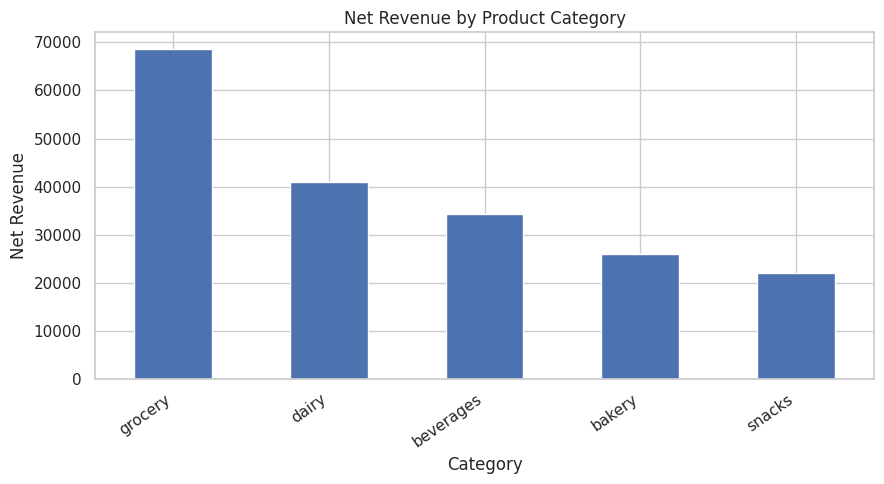

In [ ]:
category_revenue = (
    analysis.groupby("category", dropna=False)["net_revenue"]
    .sum().sort_values(ascending=False)
)
display(category_revenue.rename("net_revenue").to_frame())

category_revenue.plot(kind="bar", figsize=(9, 5))
plt.title("Net Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Net Revenue")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 11. EDA Question 2 — Which stores show increasing/decreasing sales?

,date,store_name,net_revenue
0,2026-09-01,Coimbatore Central,56268.4
1,2026-09-01,Erode Town,34304.3
2,2026-09-01,Salem Junction,59865.7
3,2026-09-01,Tiruppur Market,41307.4


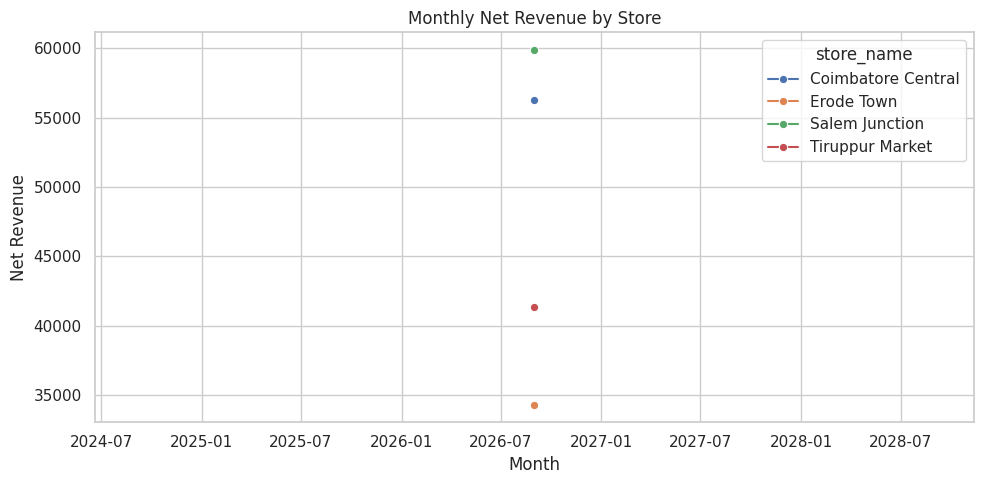

Note: this practice dataset covers only 14 days; use daily trends for more detail.


In [ ]:
monthly_store_sales = (
    analysis.groupby([pd.Grouper(key="date", freq="MS"), "store_name"], as_index=False)
    ["net_revenue"].sum()
)
display(monthly_store_sales.head(10))

plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly_store_sales, x="date", y="net_revenue",
             hue="store_name", marker="o")
plt.title("Monthly Net Revenue by Store")
plt.xlabel("Month")
plt.ylabel("Net Revenue")
plt.tight_layout()
plt.show()

# Dataset covers only 14 days, so monthly trends have limited evidence.
print("Note: this practice dataset covers only 14 days; use daily trends for more detail.")

## 12. EDA Question 3 — How do promotions affect units sold?

,average_units,total_units,transaction_count
promotion,,,
No,11.472000,2868,250
Yes,11.535714,969,84


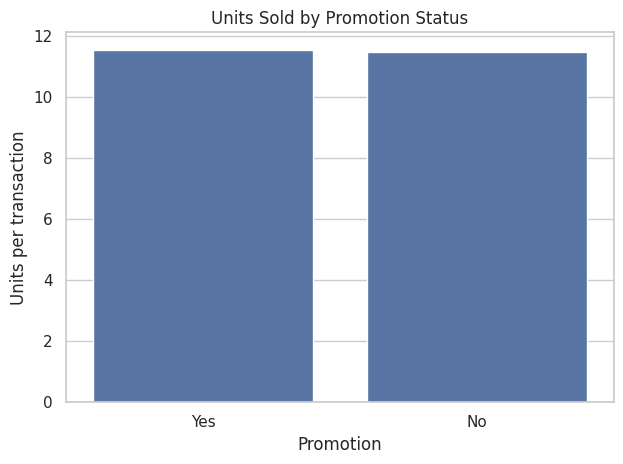

In [ ]:
promotion_summary = (
    analysis.groupby("promotion")["quantity"]
    .agg(average_units="mean", total_units="sum", transaction_count="count")
)
display(promotion_summary)

sns.barplot(data=analysis, x="promotion", y="quantity", errorbar=None)
plt.title("Units Sold by Promotion Status")
plt.xlabel("Promotion")
plt.ylabel("Units per transaction")
plt.tight_layout()
plt.show()

## 13. EDA Question 4 — Weekend vs weekday demand

,average_units,total_units,transaction_count
Weekday,11.531381,2756,239
Weekend,11.378947,1081,95


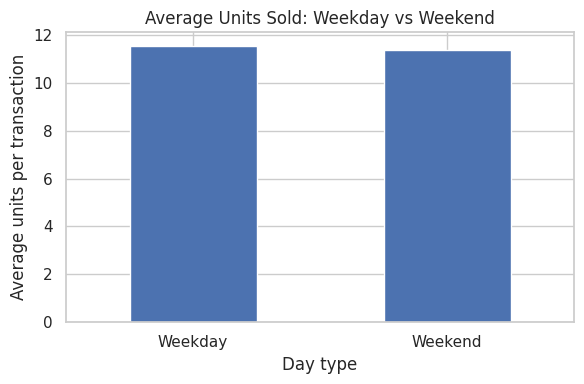

In [ ]:
weekend_summary = (
    analysis.groupby("is_weekend")["quantity"]
    .agg(average_units="mean", total_units="sum", transaction_count="count")
)
weekend_summary.index = ["Weekday" if not x else "Weekend" for x in weekend_summary.index]
display(weekend_summary)

weekend_summary["average_units"].plot(kind="bar", figsize=(6, 4))
plt.title("Average Units Sold: Weekday vs Weekend")
plt.xlabel("Day type")
plt.ylabel("Average units per transaction")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 14. EDA Question 5 — Which products have volatile demand?

,mean_daily_units,std_daily_units,coefficient_of_variation
product_id,,,
P103,15.714286,3.750458,0.238665
P104,27.928571,5.608569,0.200818
P102,47.357143,6.368276,0.134473
P101,62.642857,5.624222,0.089782
P106,39.928571,3.429830,0.085899
P105,80.500000,5.064963,0.062919


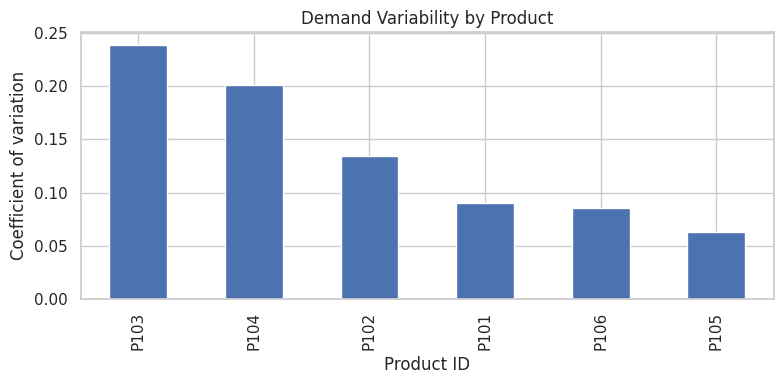

In [ ]:
product_volatility = (
    daily_sales.groupby("product_id")["quantity"]
    .agg(mean_daily_units="mean", std_daily_units="std")
)
product_volatility["coefficient_of_variation"] = (
    product_volatility["std_daily_units"] /
    product_volatility["mean_daily_units"].replace(0, np.nan)
)
product_volatility = product_volatility.sort_values(
    "coefficient_of_variation", ascending=False
)
display(product_volatility)

product_volatility["coefficient_of_variation"].dropna().plot(
    kind="bar", figsize=(8, 4)
)
plt.title("Demand Variability by Product")
plt.xlabel("Product ID")
plt.ylabel("Coefficient of variation")
plt.tight_layout()
plt.show()

## 15. EDA Question 6 — Where are stock-outs/low-stock warnings frequent?

In [ ]:
stock_summary = (
    inventory_clean.groupby(["store_id", "product_id"])
    .agg(
        below_reorder_records=("below_reorder_level", "sum"),
        zero_stock_records=("is_zero_stock", "sum"),
        observations=("date", "count"),
        average_closing_stock=("closing", "mean")
    )
    .reset_index()
    .sort_values(["zero_stock_records", "below_reorder_records"], ascending=False)
)
display(stock_summary.head(15))

print("Below reorder level means stock needs attention; it does not automatically mean a stock-out.")

,store_id,product_id,below_reorder_records,zero_stock_records,observations,average_closing_stock
0,S01,P101,0,0,14,20.071429
1,S01,P102,0,0,14,28.500000
2,S01,P103,0,0,14,41.928571
3,S01,P104,0,0,14,42.785714
4,S01,P105,0,0,14,30.642857
5,S01,P106,0,0,14,46.500000
6,S02,P101,0,0,14,27.500000
7,S02,P102,0,0,14,34.928571
8,S02,P103,0,0,14,46.142857
9,S02,P104,0,0,14,47.642857


Below reorder level means stock needs attention; it does not automatically mean a stock-out.


## 16. Explore external factors and numeric relationships

\nAverage units sold by weather:


,mean,sum,count
weather,,,
Cloudy,11.652632,1107,95
Rainy,11.569444,833,72
Unknown,11.425532,537,47
Sunny,11.333333,1360,120


\nAverage units sold by holiday:


,mean,sum,count
holiday,,,
Yes,11.520833,553,48
No,11.482517,3284,286


\nAverage units sold by festival:


,mean,sum,count
festival,,,
No,11.555133,3039,263
Yes,11.239437,798,71


\nAverage units sold by local_event:


,mean,sum,count
local_event,,,
Yes,12.250000,294,24
No,11.429032,3543,310


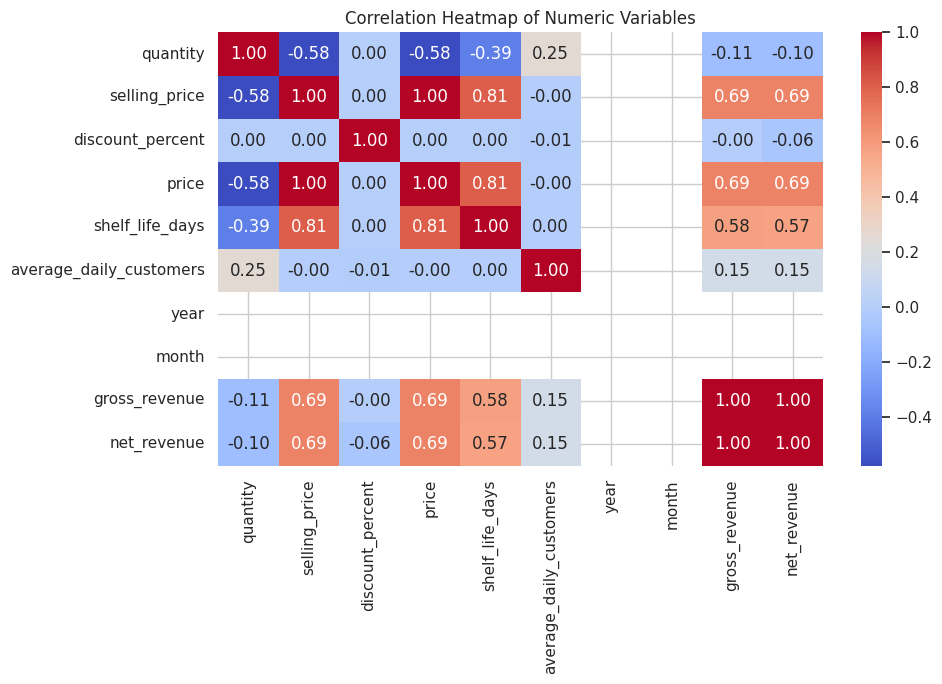

In [ ]:
for factor in ["weather", "holiday", "festival", "local_event"]:
    if factor in analysis.columns:
        print(f"\\nAverage units sold by {factor}:")
        display(
            analysis.groupby(factor, dropna=False)["quantity"]
            .agg(["mean", "sum", "count"])
            .sort_values("mean", ascending=False)
        )

numeric_cols = analysis.select_dtypes(include="number")
plt.figure(figsize=(10, 7))
sns.heatmap(numeric_cols.corr(), cmap="coolwarm", annot=True, fmt=".2f")
plt.title("Correlation Heatmap of Numeric Variables")
plt.tight_layout()
plt.show()

## 17. Categorical encoding example

In [ ]:
categorical_columns = [
    col for col in ["category", "brand", "store_type", "region", "weather"]
    if col in analysis.columns
]
encoded_sample = pd.get_dummies(
    analysis, columns=categorical_columns, dtype=int
)
print("Original shape:", analysis.shape)
print("Encoded shape:", encoded_sample.shape)
display(encoded_sample.head())

Original shape: (334, 29)
Encoded shape: (334, 42)


,transaction_id,date,store_id,product_id,quantity,selling_price,discount_percent,promotion,product_name,price,shelf_life_days,supplier,store_name,city,average_daily_customers,holiday,festival,local_event,year,month,day_of_week,is_weekend,gross_revenue,net_revenue,category_bakery,category_beverages,category_dairy,category_grocery,category_snacks,brand_BakeWell,brand_Crunchy,brand_FreshFarm,brand_FruitSip,brand_GrainGold,store_type_Mini Store,store_type_Supermarket,region_North,region_West,weather_Cloudy,weather_Rainy,weather_Sunny,weather_Unknown
0,T0001,2026-09-01,S01,P101,20,32,10,Yes,Milk 1L,32,7,DailyDairy,Coimbatore Central,Coimbatore,420,No,No,No,2026,9,Tuesday,False,640,576.0,0,0,1,0,0,0,0,1,0,0,0,1,0,1,0,0,1,0
1,T0002,2026-09-01,S01,P102,17,40,0,No,Bread,40,3,DailyDairy,Coimbatore Central,Coimbatore,420,No,No,No,2026,9,Tuesday,False,680,680.0,1,0,0,0,0,1,0,0,0,0,0,1,0,1,0,0,1,0
2,T0003,2026-09-01,S01,P103,1,320,0,No,Rice 5kg,320,180,GrainSupply,Coimbatore Central,Coimbatore,420,No,No,No,2026,9,Tuesday,False,320,320.0,0,0,0,1,0,0,0,0,0,1,0,1,0,1,0,0,1,0
3,T0004,2026-09-01,S01,P104,5,90,0,No,Apple Juice,90,120,CoolDrinks,Coimbatore Central,Coimbatore,420,No,No,No,2026,9,Tuesday,False,450,450.0,0,1,0,0,0,0,0,0,1,0,0,1,0,1,0,0,1,0
4,T0005,2026-09-01,S01,P105,24,20,10,Yes,Potato Chips,20,90,SnackHub,Coimbatore Central,Coimbatore,420,No,No,No,2026,9,Tuesday,False,480,432.0,0,0,0,0,1,0,1,0,0,0,0,1,0,1,0,0,1,0


## 18. Basic feature selection example

In [ ]:
# This is an exploratory correlation check, not a complete predictive model.
numeric_features = analysis.select_dtypes(include="number")
if "quantity" in numeric_features.columns:
    quantity_correlations = (
        numeric_features.corr()["quantity"]
        .drop(labels=["quantity"], errors="ignore")
        .sort_values(key=lambda s: s.abs(), ascending=False)
    )
    display(quantity_correlations.to_frame("correlation_with_quantity"))
print("Choose features using business knowledge too; correlation does not prove causation.")

,correlation_with_quantity
selling_price,-0.576625
price,-0.576625
shelf_life_days,-0.387921
average_daily_customers,0.251747
gross_revenue,-0.105347
net_revenue,-0.104931
discount_percent,0.004070
year,NaN
month,NaN


Choose features using business knowledge too; correlation does not prove causation.
